In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, 
    roc_auc_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix, 
    ConfusionMatrixDisplay, 
    roc_curve
)

In [2]:
df = pd.read_parquet("../data/processed/clean.parquet")
print(f"{len(df):,} transactions")

776,579 transactions


In [3]:
INK = "#1f2933"
MUTED = "#6b7280"
GRID = "#e5e7eb"
BASE = "#4a78b0"
ACCENT = "#e07a2f"

# 5.1 Intentional error

In [4]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
naive = (
    df.groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate", lambda s: (reference_date - s.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("TotalPrice", "sum")
        )
)

naive["Goal"] = (naive["Recency"] <= 30).astype(int)
x_naive = naive[["Recency", "Frequency", "Monetary"]]
y_naive = naive["Goal"]

x_tr_n, x_te_n, y_tr_n, y_te_n = train_test_split(x_naive, y_naive, test_size=0.3, random_state=42, stratify=y_naive)

m_naive = Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=1000))])
m_naive.fit(x_tr_n, y_tr_n)

y_pred_n = m_naive.predict(x_te_n)
y_prob_n = m_naive.predict_proba(x_te_n)[:, 1]

print("=== BROKEN MODEL (data leakage) ===")
print(f"Accuracy : {accuracy_score(y_te_n, y_pred_n):.4f}")
print(f"ROC AUC : {roc_auc_score(y_te_n, y_prob_n):.4f}")

=== BROKEN MODEL (data leakage) ===
Accuracy : 0.9801
ROC AUC : 0.9998


# 5.2 Time-based Split

In [5]:
end = df["InvoiceDate"].max()
cut = end - pd.Timedelta(days=90)

print(f"Maximum date in dataset: {end}")
print(f"Cutoff date (90 days before end): {cut.date()}")

past  = df[df["InvoiceDate"] <= cut].copy()
future = df[df["InvoiceDate"] >  cut].copy()

print(f"Number of past transactions:   {len(past):,}")
print(f"Number of future transactions: {len(future):,}")

Maximum date in dataset: 2011-12-09 12:50:00
Cutoff date (90 days before end): 2011-09-10
Number of past transactions:   618,316
Number of future transactions: 158,263


# 5.3 Feature Engineering

In [6]:
features = (past.groupby("CustomerID")
     .agg(Recency=("InvoiceDate", lambda s: (cut - s.max()).days),
          Frequency=("InvoiceNo", "nunique"),
          Monetary=("TotalPrice", "sum"),
          NumberOfItems=("InvoiceNo", "size"),
          DistinctProducts=("StockCode", "nunique"),
          FirstPurchase=("InvoiceDate", "min"),
          AverageQuantity=("Quantity", "mean"),
          AveragePrice=("UnitPrice", "mean"),
          Country=("Country", "first"))
)

features["AverageCart"]  = features["Monetary"] / features["Frequency"]
features["CustomerTenure"]  = (cut - features["FirstPurchase"]).dt.days
features["AverageDaysBetweenPurchases"] = np.where(features["Frequency"] > 1,
                               features["CustomerTenure"] / (features["Frequency"] - 1),
                               features["CustomerTenure"])
features["IsUK"] = (features["Country"] == "United Kingdom").astype(int)

almost = past[past["InvoiceDate"] > cut - pd.Timedelta(days=90)]
features["OrdersLast90Days"] = almost.groupby("CustomerID")["InvoiceNo"].nunique().reindex(features.index).fillna(0)
features["SpendingLast90Days"]  = almost.groupby("CustomerID")["TotalPrice"].sum().reindex(features.index).fillna(0)

customers_future = set(future["CustomerID"].unique())
features["Goal"] = features.index.isin(customers_future).astype(int)

features = features.drop(columns=["FirstPurchase", "Country"])

print(f"Number of customers: {len(features):,}")
print(f"Customers that came back: {features['Goal'].sum():,} ({features['Goal'].mean()*100:.1f}%)")
print(f"Customers that didn't come back: {(features['Goal'] == 0).sum():,} ({(1 - features['Goal'].mean())*100:.1f}%)")
features.head()

Number of customers: 5,256
Customers that came back: 2,289 (43.6%)
Customers that didn't come back: 2,967 (56.4%)


,Recency,Frequency,Monetary,NumberOfItems,DistinctProducts,AverageQuantity,AveragePrice,AverageCart,CustomerTenure,AverageDaysBetweenPurchases,IsUK,OrdersLast90Days,SpendingLast90Days,Goal
CustomerID,,,,,,,,,,,,,,
12346,235,3,77352.96,25,25,2969.560000,6.816000,25784.320,556,278.000000,1,0.0,0.00,0
12347,39,6,3402.39,164,107,12.798780,2.562622,567.065,313,62.600000,0,1.0,584.91,1
12348,158,4,1388.40,44,24,56.545455,0.672727,347.100,347,115.666667,0,0.0,0.00,1
12349,317,2,2221.14,100,89,9.910000,4.253400,1110.570,498,498.000000,0,0.0,0.00,1
12350,219,1,294.40,16,16,12.250000,1.581250,294.400,219,219.000000,0,0.0,0.00,0


# 5.4 Training and evaluation

In [7]:
features_cols = [col for col in features.columns if col != "Goal"]

x_tr, x_te, y_tr, y_te = train_test_split(
    features[features_cols], features["Goal"], test_size=0.25, random_state=42, stratify=features["Goal"]
)

print(f"Training set: {len(x_tr):,} customers")
print(f"Test set    : {len(x_te):,} customers")

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "LogisticRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=20,
        class_weight="balanced", 
        random_state=42, 
        n_jobs=-1
    )
}

results = []
predictions = {}
probs = {}

for name, model in models.items():
    model.fit(x_tr, y_tr)
    p = model.predict(x_te)
    predictions[name] = p

    try:
        prob = model.predict_proba(x_te)[:, 1]
        auc = roc_auc_score(y_te, prob)
        probs[name] = prob
    except Exception:
        auc = 0.5
        probs[name] = np.zeros(len(y_te))
    
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_te, p),
        "Precision": precision_score(y_te, p, zero_division=0),
        "Recall": recall_score(y_te, p, zero_division=0),
        "F1 score": f1_score(y_te, p, zero_division=0),
        "ROC AUC": auc
    })

eval_table = pd.DataFrame(results)
eval_table

Training set: 3,942 customers
Test set    : 1,314 customers


,Model,Accuracy,Precision,Recall,F1 score,ROC AUC
0,Baseline,0.564688,0.000000,0.000000,0.000000,0.500000
1,LogisticRegression,0.731355,0.691769,0.690559,0.691164,0.794906
2,Random Forest,0.743531,0.720450,0.671329,0.695023,0.804700


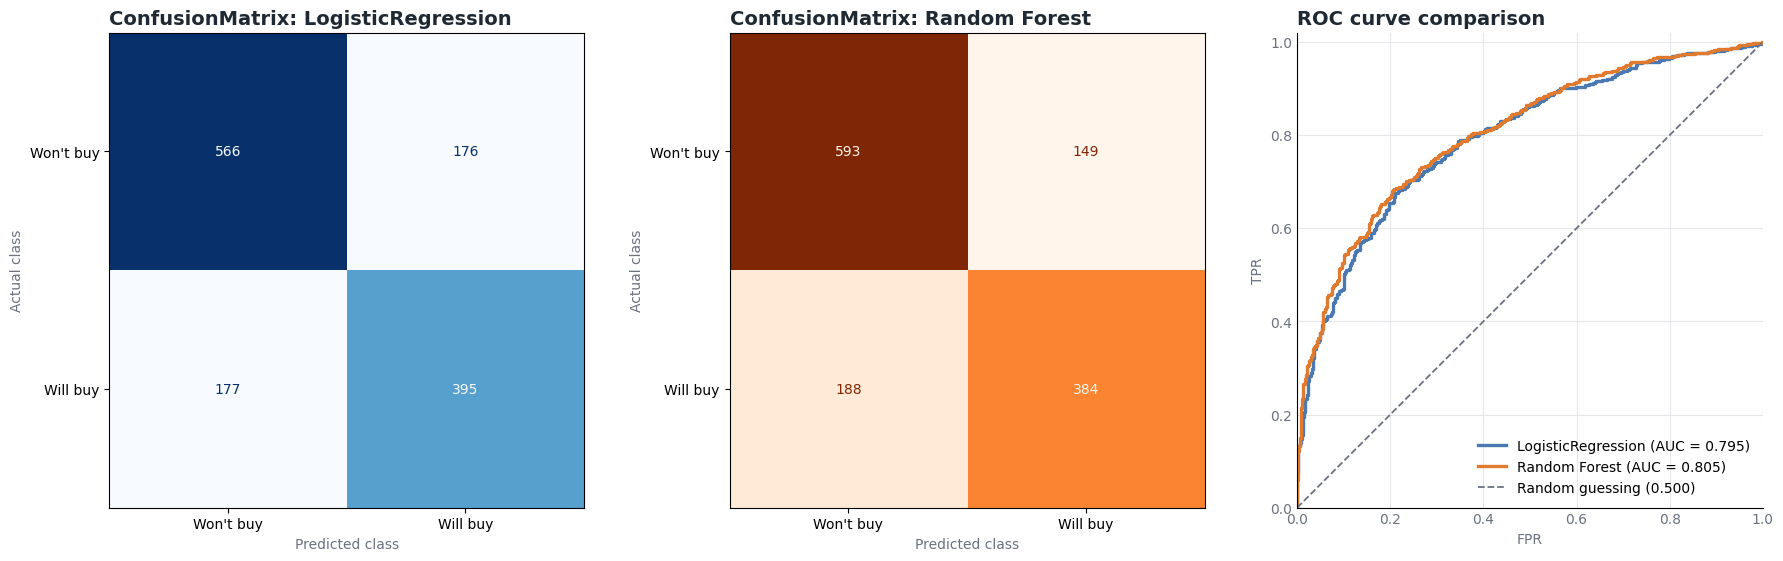

In [9]:
model_colors = {"LogisticRegression": "#4a78b0", "Random Forest": "#e07a2f"}
model_cmaps  = {"LogisticRegression": "Blues",   "Random Forest": "Oranges"}
labels = ["Won't buy", "Will buy"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), constrained_layout=True)

for ax, name in zip(axes[:2], ["LogisticRegression", "Random Forest"]):
    cm = confusion_matrix(y_te, predictions[name])
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(
        ax=ax,
        cmap=model_cmaps[name], 
        colorbar=False, 
        values_format="d"
    )
    ax.set_title(
        f"ConfusionMatrix: {name}", 
        loc="left",
        fontsize=14, 
        fontweight="bold", 
        color=INK
    )
    ax.set_xlabel("Predicted class", color=MUTED)
    ax.set_ylabel("Actual class", color=MUTED)
    ax.grid(False)

ax = axes[2]
for name in probs:
    if name == "Baseline":
        continue

    fpr, tpr, _ = roc_curve(y_te, probs[name])
    auc = roc_auc_score(y_te, probs[name])
    ax.plot(
        fpr, 
        tpr, 
        linewidth=2.4, 
        color=model_colors.get(name, "#2a9d8f"),
        label=f"{name} (AUC = {auc:.3f})"
    )

ax.plot(
    [0, 1], 
    [0, 1], 
    color=MUTED, 
    linestyle="--", 
    linewidth=1.3,
    label="Random guessing (0.500)"
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("FPR", color=MUTED)
ax.set_ylabel("TPR", color=MUTED)

ax.set_title("ROC curve comparison", loc="left", fontsize=14, fontweight="bold", color=INK)
ax.tick_params(colors=MUTED, length=0)
ax.set_axisbelow(True)
ax.grid(True, color=GRID, linewidth=0.8)

for side in ("top", "right"):
    ax.spines[side].set_visible(False)

ax.legend(frameon=False, loc="lower right")
plt.show()

# 5.5 Feature Importance

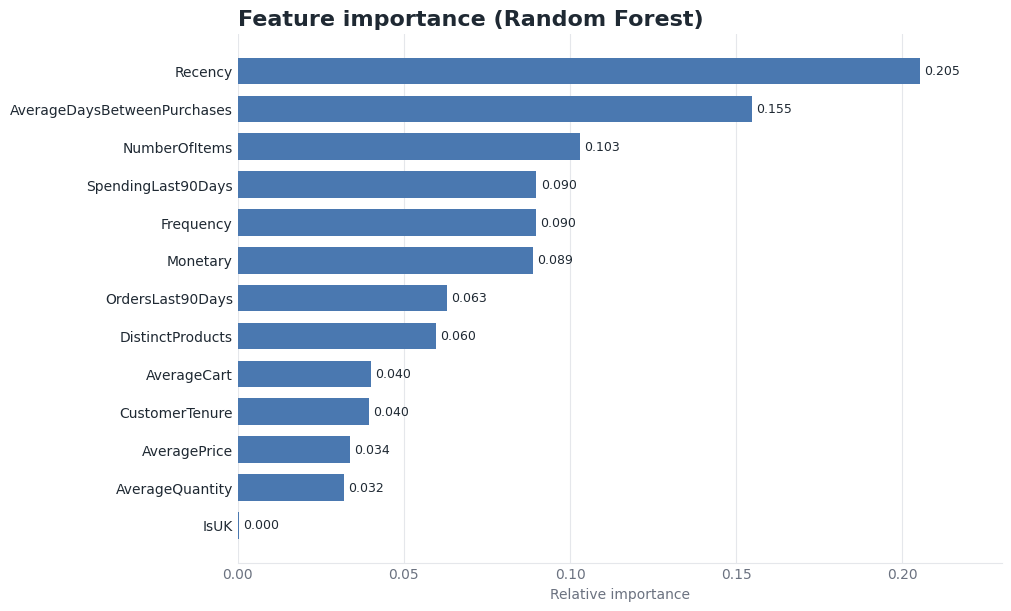

In [11]:
rf_model = models["Random Forest"]
importance = pd.Series(rf_model.feature_importances_, index=features_cols).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

bars = ax.barh(importance.index, importance.values, color=BASE, height=0.7)
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9, color=INK)

ax.set_title(
    "Feature importance (Random Forest)", 
    loc="left",
    fontsize=16, 
    fontweight="bold", 
    color=INK
)
ax.set_xlabel("Relative importance", color=MUTED)
ax.margins(x=0.12)

ax.tick_params(colors=MUTED, length=0)
ax.tick_params(axis="y", labelcolor=INK, labelsize=10)
ax.set_axisbelow(True)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)

for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)

ax.spines["bottom"].set_color(GRID)

plt.show()

In [12]:
features.to_parquet("../data/processed/data_model.parquet")